# GR05 · Task 3 — Understanding our engine data
## From HDF5 arrays to a defensible explanation
**Selçuk Ata Aksoy · Denzel Gregory Pragassa**  
Industrial Analytics · HFU · WS 2026/27 · 22 October 2026

This is a guided investigation of the **actual local DS01 and DS02 files**, not a model-training notebook. Read the explanations, run cells from top to bottom, and use the questions to practise explaining the dataset in your own words.

**By the end you should be able to explain:** what one row represents; the features and their measurement scales; the difference between an engine, a flight, and a reading; how RUL labels behave; what data quality was checked; why operating conditions complicate interpretation; and what is still uncertain.

**Task mapping.** The supplied `IBS6 Industrial Analytics Project Tasks V3.0.pdf`, p. 1, requests structure/features, data types/distributions, missing values/anomalies, and an exploratory notebook containing feature descriptions, visualizations, summary statistics, and a data quality report. Its internal heading says V12.0 despite the filename; we identify it by filename and 22 October date. This notebook addresses those deliverables. No prediction results are claimed.

### Reading map
1. Setup and source evidence
2. Files and HDF5 structure
3. Feature dictionary and a small row example
4. Full numeric audit and engine/flight summaries
5. RUL, flight profiles, operating conditions, sensors, and correlations
6. The six quality dimensions
7. Limitations, presentation questions, and reproducible exports

**Scope labels matter:** “full scan” means every stored numeric cell in both files; “sample” means deterministic evenly spaced rows; “cycle mean” means all readings in one engine-flight averaged together. None of these is a random train/test split.

## 1 · Setup — run once per session
From the repository root:
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m jupyterlab
```
Select the `.venv` Python interpreter/kernel. A full run reads approximately 5 GB plus a checksum pass. It may take several minutes, but arrays are processed in 100,000-row chunks. It creates small reports and figures; it **never modifies the raw HDF5 files**. If files are missing, the next cell explains which paths are expected.

In [1]:
from pathlib import Path
import sys, json, platform
from datetime import datetime
from zoneinfo import ZoneInfo

# Works when Jupyter starts either at the repository root or in notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/data_understanding.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the GR05 repository.')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data_understanding import (
    GROUPS, column_names, file_inventory, feature_dictionary, scan_file,
    engine_summary, consistency_report, outlier_screen, first_flight,
    source_manifest, environment_versions, lecturer_feature_table,
)

PATHS = [ROOT / 'data/raw/N-CMAPSS_DS01-005.h5',
         ROOT / 'data/raw/N-CMAPSS_DS02-006.h5']
for path in PATHS:
    if not path.is_file():
        raise FileNotFoundError(f'Place the Kaggle file here: {path}')
RESULTS, FIGURES = ROOT / 'reports/results', ROOT / 'reports/figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
CHUNK_ROWS, SAMPLE_ROWS = 100_000, 12_000  # diagnostic sample per partition
ANALYSIS_DATE = datetime.now(ZoneInfo('Europe/Berlin')).date().isoformat()
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (11, 5),
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.size': 10,
                     'axes.prop_cycle': plt.cycler(color=['#c3441f','#386757','#b38b48','#617f98','#796d8f','#7c8d43'])})

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.svg', bbox_inches='tight', metadata={'Date': None})
    plt.show()
    plt.close(fig)

versions = environment_versions()
display(pd.Series(versions, name='installed version').to_frame())

,installed version
python,3.12.3
numpy,2.5.4
pandas,3.0.6
h5py,3.16.0
matplotlib,3.11.2
jupyterlab,4.6.4
nbclient,0.11.0
nbformat,5.11.1


### What are the source materials?
- **Local binary files:** authoritative evidence for shapes, values, identifiers, and observed quality checks.
- **Kaggle accompanying PDF:** `data/Run_to_Failure_Simulation_Under_Real_Flight_Conditions_Dataset.pdf`. This is a **7-page preprint dated 20 April 2020**, focused on the nine-unit scenario corresponding to DS02; it is not the 2021 journal paper covering all dataset groups. Tables 1–4 describe variables and units; pp. 3–5 explain DS02 and a 1 Hz sampling rate. The files do not contain explicit timestamps, so we use **row index** rather than claiming verified wall-clock timestamps.
- **Kaggle example notebook:** `data/N-CMAPSS_Example_data_loading_and_exploration.ipynb`, credited to Manuel Arias. We read it as a reference, not as code to run blindly: it loads whole arrays and concatenates development/test data. We preserve the supplied split and use chunks. Its flight-class paragraph repeats “class 2” for long flights; the accompanying table says class 3. That typo is not copied here.
- **Journal reference:** Arias Chao et al. (2021), [Data 6(1), 5](https://doi.org/10.3390/data6010005), for the wider N-CMAPSS collection. The supplied preprint and local fields differ in places; do not silently assume that every table version is identical.
- **Additional lecturer guides:** `IBS6 Industrial Analytics - Dataset Scales.pptx`, slides 3–4, and `Task 3 - Describe Data - Feature Description Table - Data Types.ipynb` (Airbnb example): scales, valid operations, feature summaries, and explicit dtype adjustments.
- **Lecturer materials:** task sheet p. 1; *Industrial Analytics — Introduction V2.0*, pp. 10–11 (descriptive vs predictive analytics); *Data Science — Introduction V1.0*, pp. 9–12 (systematic process, context, overfitting); the supplied “Verify Data Quality” screenshot (six quality dimensions). The screenshot is a user-provided excerpt, not a slide we located in the supplied decks.

**Provenance still open:** download date/version identifier, Kaggle redistribution terms, and upstream checksum comparison. A locally computed hash proves which bytes we analysed, not licensing or authenticity.

## 2 · What is actually inside our files?
HDF5 is a container of named arrays. `W_dev` means operating conditions for development engines. `X_s_test` means measured sensor signals for the provided test engines. The suffix is a **partition**, not a sensor name.

Each row aligns across the six arrays within the same file and partition. Metadata arrays ending in `_var` hold the column names, encoded as bytes. We decode them rather than inventing a CSV header.

In [2]:
inventory = file_inventory(PATHS)
display(inventory[['dataset','array','shape','dtype','array_bytes']])
file_sizes = inventory[['dataset','file','file_bytes']].drop_duplicates().copy()
file_sizes['GiB'] = file_sizes.file_bytes / 1024**3
display(file_sizes)
# Peek at a few rows only: this does not load a full dataset.
with h5py.File(PATHS[0], 'r') as hdf:
    print('Top-level names:', list(hdf.keys()))
    print('Raw feature metadata:', hdf['W_var'][:])

,dataset,array,shape,dtype,array_bytes
0,DS01,A_dev,"(4906636, 4)",float64,157012352
1,DS01,A_test,"(2735232, 4)",float64,87527424
2,DS01,A_var,"(4,)",|S5,20
3,DS01,T_dev,"(4906636, 10)",float64,392530880
4,DS01,T_test,"(2735232, 10)",float64,218818560
5,DS01,T_var,"(10,)",|S12,120
6,DS01,W_dev,"(4906636, 4)",float64,157012352
7,DS01,W_test,"(2735232, 4)",float64,87527424
8,DS01,W_var,"(4,)",|S4,16
9,DS01,X_s_dev,"(4906636, 14)",float64,549543232


,dataset,file,file_bytes,GiB
0,DS01,N-CMAPSS_DS01-005.h5,2873351432,2.676017
17,DS02,N-CMAPSS_DS02-006.h5,2450472504,2.282180


Top-level names: ['A_dev', 'A_test', 'A_var', 'T_dev', 'T_test', 'T_var', 'W_dev', 'W_test', 'W_var', 'X_s_dev', 'X_s_test', 'X_s_var', 'X_v_dev', 'X_v_test', 'X_v_var', 'Y_dev', 'Y_test']
Raw feature metadata: [b'alt' b'Mach' b'TRA' b'T2']


### How to explain the six blocks
| Block | Meaning | Intended use later |
|---|---|---|
| `W` | Flight operating conditions | Candidate predictors |
| `X_s` | Measured sensor channels (simulation outputs) | Candidate predictors |
| `X_v` | Virtual/unobserved simulator signals | Exclude from our first real-sensor baseline |
| `T` | Underlying component health modifiers | Diagnostics only; not realistically available predictors |
| `Y` | Remaining useful life label | Target only |
| `A` | Engine, cycle, flight class, health-state metadata | Grouping, ordering, diagnostics; exclude from first baseline |

“Measured” identifies a channel type inside the simulator; it does **not** mean actual engine failures were measured. Counting every stored variable as a usable predictor would be misleading.

## 3 · What do the variables mean?
The table below is the feature description deliverable: physical meaning, storage type, unit, measurement scale, and intended role.

**Storage type ≠ statistical meaning.** A float64 engine ID is still a nominal identifier. Flight class is ordered (short/medium/long); the numerical codes are not distances. `hs` is a retrospective simulator health label, not a safe input for operational RUL prediction. A temperature in Rankine is an absolute temperature; it is not Celsius. Altitude is treated as interval-scaled because its zero is a reference datum; physical ratios of altitude labels are not interpreted.

**Engine glossary:** fan → LPC (low-pressure compressor) → HPC (high-pressure compressor) → burner → HPT (high-pressure turbine) → LPT (low-pressure turbine). Temperatures, pressures, speeds, and flows describe different stations in that path. `psia` means absolute pressure in pounds per square inch; `rpm` means revolutions per minute.

**Source discrepancy to remember:** the local file has `P2`, which the supplied older preprint's measured-sensor table omits. We flag its definition/unit for confirmation rather than pretending the table establishes them. Likewise the preprint lists virtual quantities not present in these files. The local metadata determines actual column membership.

In [3]:
dictionary = feature_dictionary(PATHS[0])
# Ensure DS02 has the same columns; separate data do not imply identical trajectories.
with h5py.File(PATHS[0], 'r') as first, h5py.File(PATHS[1], 'r') as second:
    assert all(column_names(first, g) == column_names(second, g) for g in GROUPS)
display(dictionary)
print('Stored fields:', len(dictionary))
print('Candidate W + X_s predictors:', int(dictionary.group.isin(['W','X_s']).sum()))
dictionary.to_csv(RESULTS / 'feature_dictionary.csv', index=False)

with h5py.File(PATHS[0], 'r') as hdf:
    preview = pd.DataFrame(np.column_stack([hdf['A_dev'][:5], hdf['W_dev'][:5],
                                            hdf['X_s_dev'][:5], hdf['Y_dev'][:5]]),
                           columns=column_names(hdf,'A') + column_names(hdf,'W') +
                                   column_names(hdf,'X_s') + ['RUL'])
display(preview)

,group,feature,dtype,description,unit,role,attribute_type,variability,scale,operators,scale_reason
0,W,alt,float64,Altitude,ft,candidate predictor,quantitative (metric),continuous,Interval,"==, !=, <, <=, >, >=, +, -",Altitude uses a reference datum; sea-level zer...
1,W,Mach,float64,Flight Mach number,dimensionless,candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
2,W,TRA,float64,Throttle-resolver angle,%,candidate predictor,quantitative (metric),continuous,Interval,"==, !=, <, <=, >, >=, +, -",Working classification: control-position scale...
3,W,T2,float64,Total temperature at fan inlet,°R (Rankine),candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
4,X_s,T24,float64,Total temperature at LPC outlet,°R (Rankine),candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
5,X_s,T30,float64,Total temperature at HPC outlet,°R (Rankine),candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
6,X_s,T48,float64,Total temperature at HPT outlet,°R (Rankine),candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
7,X_s,T50,float64,Total temperature at LPT outlet,°R (Rankine),candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
8,X_s,P15,float64,Total pressure in bypass duct,psia,candidate predictor,quantitative (metric),continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /","Absolute temperature, speed, flow, pressure, o..."
9,X_s,P2,float64,Inlet pressure; interpretation/unit require so...,not confirmed,candidate predictor,quantitative (metric),continuous,Unconfirmed,Confirm semantics first,Confirm source definition/zero-point conventio...


Stored fields: 47
Candidate W + X_s predictors: 18


,unit,cycle,Fc,hs,alt,Mach,...,P40,P50,Nf,Nc,Wf,RUL
0,1.0,1.0,1.0,1.0,3013.0,0.376362,...,401.205188,15.974771,2142.253462,8693.176503,4.621622,99.0
1,1.0,1.0,1.0,1.0,3020.0,0.376866,...,401.132851,15.970518,2142.218596,8693.000298,4.620561,99.0
2,1.0,1.0,1.0,1.0,3025.0,0.377685,...,401.171401,15.969419,2142.257956,8693.106262,4.621064,99.0
3,1.0,1.0,1.0,1.0,3035.0,0.376992,...,401.272707,15.967762,2142.794673,8693.680367,4.624305,99.0
4,1.0,1.0,1.0,1.0,3043.0,0.377622,...,401.234620,15.962571,2143.015150,8693.714825,4.622768,99.0


**Read a row aloud:** “For one sensor reading of engine `unit`, in flight `cycle`, under altitude/Mach/throttle/temperature conditions `W`, we observe sensor channels `X_s`. The historical RUL label tells how many flight cycles remain until the simulated end-of-life.”

Several readings share engine ID, cycle, and RUL. That is expected, because a complete flight contains many samples. `(dataset, unit, cycle)` identifies a **flight**, not a unique sensor reading. Keep dataset + partition + row index for a reading's identity.

## 4 · Scan the complete files without loading them whole
This is the slowest cell. It checks all six blocks in both partitions for alignment, non-finite values, ranges, means, and standard deviations. It also constructs small **engine-flight aggregates** from every `W` and `X_s` reading. Standard deviations use a stable chunk-combination formula.

The implementation lives in `src/data_understanding.py` so the reading mechanics are reusable; it contains no fitted model. You can open it to inspect the loops. The evenly spaced sample is only for compact diagnostics. It is not used to claim population quantiles or prove that all possible duplicates are absent.

In [4]:
audits = [scan_file(path, chunk_rows=CHUNK_ROWS, sample_rows=SAMPLE_ROWS) for path in PATHS]
stats = pd.concat([a['stats'] for a in audits], ignore_index=True)
cycles = pd.concat([a['cycles'] for a in audits], ignore_index=True)
sample = pd.concat([a['sample'] for a in audits], ignore_index=True)
checks = pd.concat([a['checks'] for a in audits], ignore_index=True)
engines = engine_summary(cycles)
consistency = consistency_report(cycles)

# A unit identifier is scoped by dataset: do not merge shared unit IDs across subsets or assume their independence.
overlap = {ds: sorted(set(rows.loc[rows.partition=='dev','unit']) &
                       set(rows.loc[rows.partition=='test','unit']))
           for ds, rows in engines.groupby('dataset')}
print('Development/test engine overlap within each dataset:', overlap)
assert all(not values for values in overlap.values())
display(checks)
display(engines)

DS01 / dev: scanned 4,906,636 rows across all 47 fields


DS01 / test: scanned 2,735,232 rows across all 47 fields


DS02 / dev: scanned 5,263,447 rows across all 47 fields


DS02 / test: scanned 1,253,743 rows across all 47 fields


Development/test engine overlap within each dataset: {'DS01': [], 'DS02': []}


,dataset,partition,rows,aligned,invalid_categories,invalid_indices,within_unit_cycle_reversals,adjacent_exact_duplicates,diagnostic_sample_rows,sample_exact_duplicates
0,DS01,dev,4906636,True,0,0,0,0,12000,0
1,DS01,test,2735232,True,0,0,0,0,12000,0
2,DS02,dev,5263447,True,0,0,0,0,12000,0
3,DS02,test,1253743,True,0,0,0,0,12000,0


,dataset,partition,unit,readings,cycles,first_cycle,...,rul_min,rul_max,flight_class,flight_class_max,healthy_cycles,mean_altitude
0,DS01,dev,1,433325,100,1,...,0.0,99.0,1.0,1.0,36.0,8922.893784
1,DS01,dev,2,1049088,75,1,...,0.0,74.0,3.0,3.0,18.0,18649.291913
2,DS01,dev,3,893054,100,1,...,0.0,99.0,2.0,2.0,25.0,14419.135575
3,DS01,dev,4,414172,95,1,...,0.0,94.0,1.0,1.0,37.0,8860.747134
4,DS01,dev,5,1280147,89,1,...,0.0,88.0,3.0,3.0,18.0,18336.227801
5,DS01,dev,6,836850,94,1,...,0.0,93.0,2.0,2.0,24.0,14298.281386
6,DS01,test,7,392585,90,1,...,0.0,89.0,1.0,1.0,35.0,8879.712275
7,DS01,test,8,800294,89,1,...,0.0,88.0,2.0,2.0,25.0,14877.153790
8,DS01,test,9,351683,80,1,...,0.0,79.0,1.0,1.0,34.0,8805.208019
9,DS01,test,10,1190670,82,1,...,0.0,81.0,3.0,3.0,17.0,18327.472662


### Apply the lecturer's scales and feature-table examples
The new `IBS6 Industrial Analytics - Dataset Scales.pptx`, slides 3–4, distinguishes **nominal, ordinal, interval, and ratio**. Its example correctly treats identifiers as nominal and counts as ratio. Slide 3 places discrete/continuous beside interval/ratio; these are best recorded as **separate properties**: RUL is discrete **and** ratio-scaled, whereas Rankine temperature is continuous **and** ratio-scaled. Our cycle field is a sequential index (interval working interpretation); an aggregated count of flights is a ratio count.

The lecturer's `Task 3 - Describe Data - Feature Description Table - Data Types.ipynb` demonstrates `shape`, `head`, `tail`, `info`, and a table with dtype, non-null counts, uniqueness, scale, operators, range, null flags, and notes. We follow that layout and add physical units/roles. **Counts/ranges are full-scan; unique counts explicitly refer to the bounded sample** for continuous fields.

We adapt the example's inference rather than copy its defaults blindly: a mostly unique sensor value is not an identifier, and numeric dtype does not guarantee ratio scale. Domain overrides determine `unit`, `cycle`, `Fc`, and `hs`. Control position and simulator modifier scales are working interpretations; P2 and stall-margin zero conventions need source confirmation. No datetime parser is applied because these files have no date/time column.

In [5]:
feature_table = lecturer_feature_table(dictionary, stats, sample)
display(feature_table[(feature_table.dataset=='DS01') & (feature_table.partition=='dev')])
feature_table.to_csv(RESULTS / 'feature_description_table.csv', index=False)

# Teacher-style pandas inspection on a bounded diagnostic copy.
small = sample[(sample.dataset=='DS01') & (sample.partition=='dev')].copy()
print('Diagnostic sample shape:', small.shape)
display(small.head(3))
display(small.tail(3))
small.info()

# Demonstrate semantic types without rewriting raw files or the modeling data.
semantic = small[['unit','cycle','Fc','hs','RUL']].copy()
semantic['unit'] = semantic['unit'].astype('int64')
semantic['cycle'] = semantic['cycle'].astype('int64')
semantic['RUL'] = semantic['RUL'].astype('int64')
semantic['Fc'] = semantic['Fc'].astype(pd.CategoricalDtype(categories=[1,2,3], ordered=True))
semantic['hs'] = semantic['hs'].astype(pd.CategoricalDtype(categories=[0,1], ordered=False))
display(semantic.dtypes.rename('semantic pandas dtype').to_frame())
print('Fc ordered:', semantic.Fc.cat.ordered, '· hs ordered:', semantic.hs.cat.ordered)
print('An integer unit ID remains nominal even after casting.')

,dataset,partition,group,Column Name,Dtype,Non-Null (full),...,variability,Scale,Operators,Value Range (full),Null Values,Notes
0,DS01,dev,W,alt,float64,4906636,...,continuous,Interval,"==, !=, <, <=, >, >=, +, -",3001 – 35033,No,Altitude uses a reference datum; sea-level zer...
1,DS01,dev,W,Mach,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",0.000315 – 0.749259,No,"Absolute temperature, speed, flow, pressure, o..."
2,DS01,dev,W,TRA,float64,4906636,...,continuous,Interval,"==, !=, <, <=, >, >=, +, -",23.5545 – 88.7689,No,Working classification: control-position scale...
3,DS01,dev,W,T2,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",421.378 – 534.383,No,"Absolute temperature, speed, flow, pressure, o..."
4,DS01,dev,X_s,T24,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",484.197 – 634,No,"Absolute temperature, speed, flow, pressure, o..."
5,DS01,dev,X_s,T30,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",1069.98 – 1525.87,No,"Absolute temperature, speed, flow, pressure, o..."
6,DS01,dev,X_s,T48,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",955.057 – 1986.32,No,"Absolute temperature, speed, flow, pressure, o..."
7,DS01,dev,X_s,T50,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",698.428 – 1357.9,No,"Absolute temperature, speed, flow, pressure, o..."
8,DS01,dev,X_s,P15,float64,4906636,...,continuous,Ratio,"==, !=, <, <=, >, >=, +, -, *, /",5.9176 – 20.4481,No,"Absolute temperature, speed, flow, pressure, o..."
9,DS01,dev,X_s,P2,float64,4906636,...,continuous,Unconfirmed,Confirm semantics first,4.37317 – 15.6841,No,Confirm source definition/zero-point conventio...


Diagnostic sample shape: (12000, 50)


,dataset,partition,row_in_partition,alt,Mach,TRA,...,LPT_flow_mod,RUL,unit,cycle,Fc,hs
0,DS01,dev,0,3013.0,0.376362,70.311996,...,0.0,99.0,1.0,1.0,1.0,1.0
1,DS01,dev,408,6739.0,0.438102,74.794388,...,0.0,99.0,1.0,1.0,1.0,1.0
2,DS01,dev,817,10417.0,0.500787,77.167419,...,0.0,99.0,1.0,1.0,1.0,1.0


,dataset,partition,row_in_partition,alt,Mach,TRA,...,LPT_flow_mod,RUL,unit,cycle,Fc,hs
11997,DS01,dev,4905817,8215.0,0.375921,30.058380,...,0.0,0.0,6.0,94.0,2.0,0.0
11998,DS01,dev,4906226,5391.0,0.349524,25.751770,...,0.0,0.0,6.0,94.0,2.0,0.0
11999,DS01,dev,4906635,3002.0,0.201915,31.728291,...,0.0,0.0,6.0,94.0,2.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 50 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   dataset           12000 non-null  str    
 1   partition         12000 non-null  str    
 2   row_in_partition  12000 non-null  int64  
 3   alt               12000 non-null  float64
 4   Mach              12000 non-null  float64
 5   TRA               12000 non-null  float64
 6   T2                12000 non-null  float64
 7   T24               12000 non-null  float64
 8   T30               12000 non-null  float64
 9   T48               12000 non-null  float64
 10  T50               12000 non-null  float64
 11  P15               12000 non-null  float64
 12  P2                12000 non-null  float64
 13  P21               12000 non-null  float64
 14  P24               12000 non-null  float64
 15  Ps30              12000 non-null  float64
 16  P40               12000 non-null  float64
 17  P50 

,semantic pandas dtype
unit,int64
cycle,int64
Fc,category
hs,category
RUL,int64


Fc ordered: True · hs ordered: False
An integer unit ID remains nominal even after casting.


### How large is the dataset, really?
A million highly correlated readings are not a million independent engines. There are 19 dataset-scoped engine histories here; independence between subsets has not been established, and some IDs/lifetimes recur. Flight duration gives some engines many more rows than others. An observation-weighted score would give those engines extra influence; later evaluation should also report per-engine and macro-averaged errors.

The next table counts unique engine-flight pairs from full data. DS01 and DS02 are two subsets of **N-CMAPSS**; “DS02” does not mean the original 2008 C-MAPSS dataset.

,dataset,partition,engines,flights,readings,min_lifetime,max_lifetime
0,DS01,dev,6,553,4906636,75,100
1,DS01,test,4,341,2735232,80,90
2,DS02,dev,6,446,5263447,63,89
3,DS02,test,3,202,1253743,59,76


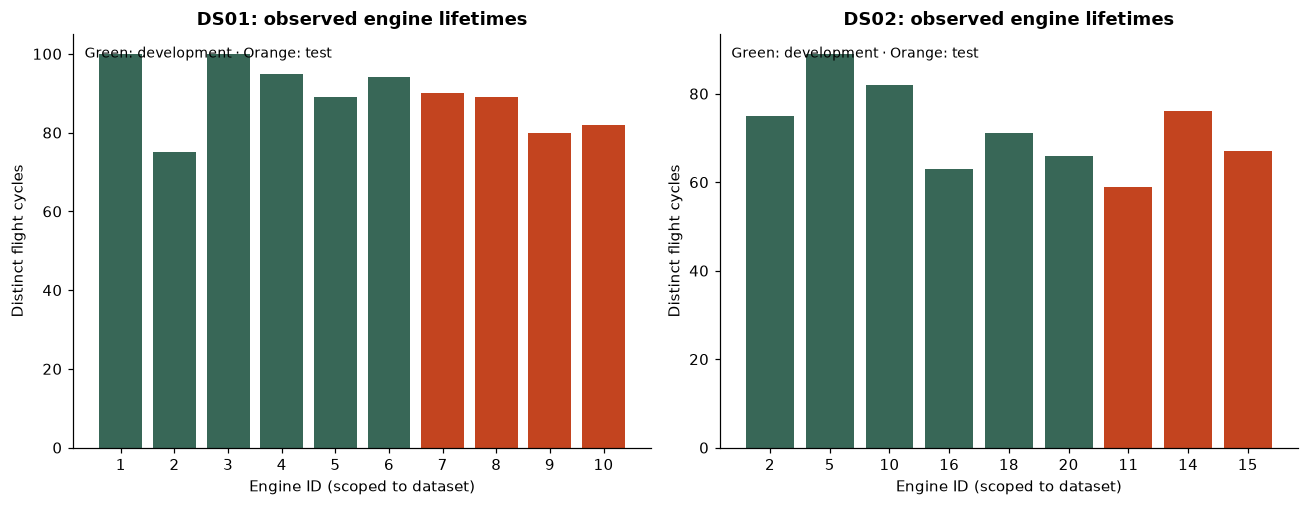

In [6]:
overview = engines.groupby(['dataset','partition'], as_index=False).agg(
    engines=('unit','nunique'), flights=('cycles','sum'), readings=('readings','sum'),
    min_lifetime=('cycles','min'), max_lifetime=('cycles','max'))
display(overview)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, (ds, rows) in zip(axes, engines.groupby('dataset')):
    colors = ['#386757' if p == 'dev' else '#c3441f' for p in rows.partition]
    ax.bar(rows.unit.astype(str), rows.cycles, color=colors)
    ax.set(title=f'{ds}: observed engine lifetimes', xlabel='Engine ID (scoped to dataset)', ylabel='Distinct flight cycles')
    ax.text(.02,.97,'Green: development · Orange: test', transform=ax.transAxes, va='top', fontsize=9)
save_figure(fig, 'engine_lifetimes')

### Summary statistics — exact vs sampled
The next table uses the **full development arrays** for means, sample standard deviations, extrema, and missing/infinite counts. The downloadable CSV also includes test structure statistics. Distribution shapes and quartiles later use labelled samples.

A zero standard deviation means a constant variable in that partition, not necessarily a broken sensor. Health modifiers can intentionally be constant if a component is not degraded in that scenario. Do not drop a variable just because it looks unusual before understanding its role.

In [7]:
display(stats[(stats.partition=='dev') & stats.group.isin(['W','X_s','Y'])][
    ['dataset','group','feature','rows','missing','infinite','minimum','maximum','mean','std']])
constant = stats[(stats.minimum == stats.maximum)]
display(constant[['dataset','partition','group','feature','minimum']])

,dataset,group,feature,rows,missing,infinite,minimum,maximum,mean,std
0,DS01,W,alt,4906636,0,0,3001.000000,35033.000000,15683.711681,8007.308449
1,DS01,W,Mach,4906636,0,0,0.000315,0.749259,0.538416,0.119401
2,DS01,W,TRA,4906636,0,0,23.554520,88.768898,60.595763,18.403906
3,DS01,W,T2,4906636,0,0,421.377893,534.383416,490.204150,19.605851
4,DS01,X_s,T24,4906636,0,0,484.197171,634.000055,569.660242,20.853293
5,DS01,X_s,T30,4906636,0,0,1069.983182,1525.868560,1330.678360,68.130229
6,DS01,X_s,T48,4906636,0,0,955.056549,1986.323386,1640.811754,123.802577
7,DS01,X_s,T50,4906636,0,0,698.427815,1357.898508,1129.690770,62.264624
8,DS01,X_s,P15,4906636,0,0,5.917596,20.448083,12.932203,2.847409
9,DS01,X_s,P2,4906636,0,0,4.373175,15.684102,10.088692,2.394340


,dataset,partition,group,feature,minimum
32,DS01,dev,T,fan_eff_mod,0.0
33,DS01,dev,T,fan_flow_mod,0.0
34,DS01,dev,T,LPC_eff_mod,0.0
35,DS01,dev,T,LPC_flow_mod,0.0
36,DS01,dev,T,HPC_eff_mod,0.0
37,DS01,dev,T,HPC_flow_mod,0.0
39,DS01,dev,T,HPT_flow_mod,0.0
40,DS01,dev,T,LPT_eff_mod,0.0
41,DS01,dev,T,LPT_flow_mod,0.0
79,DS01,test,T,fan_eff_mod,0.0


## 5 · What does RUL look like?
For a complete run-to-failure engine history, the retrospective rule to verify is:

**RUL = engine's last observed cycle − current cycle.**

The final simulated failure cycle therefore has RUL 0. This convention is not “one remaining cycle”. We check both the min and max label in every flight, so a hidden disagreement inside a cycle is detected. The last observed cycle uses future knowledge: it is valid to **audit labels**, never as an input for future prediction.

,dataset,partition,unit,inconsistent_rul_cycles,rul_formula_violations,noncontiguous_cycles,health_switch_back,mixed_health_cycles,mixed_flight_class_cycles
0,DS01,dev,1,0,0,0,0,0,0
1,DS01,dev,2,0,0,0,0,0,0
2,DS01,dev,3,0,0,0,0,0,0
3,DS01,dev,4,0,0,0,0,0,0
4,DS01,dev,5,0,0,0,0,0,0
5,DS01,dev,6,0,0,0,0,0,0
6,DS01,test,7,0,0,0,0,0,0
7,DS01,test,8,0,0,0,0,0,0
8,DS01,test,9,0,0,0,0,0,0
9,DS01,test,10,0,0,0,0,0,0


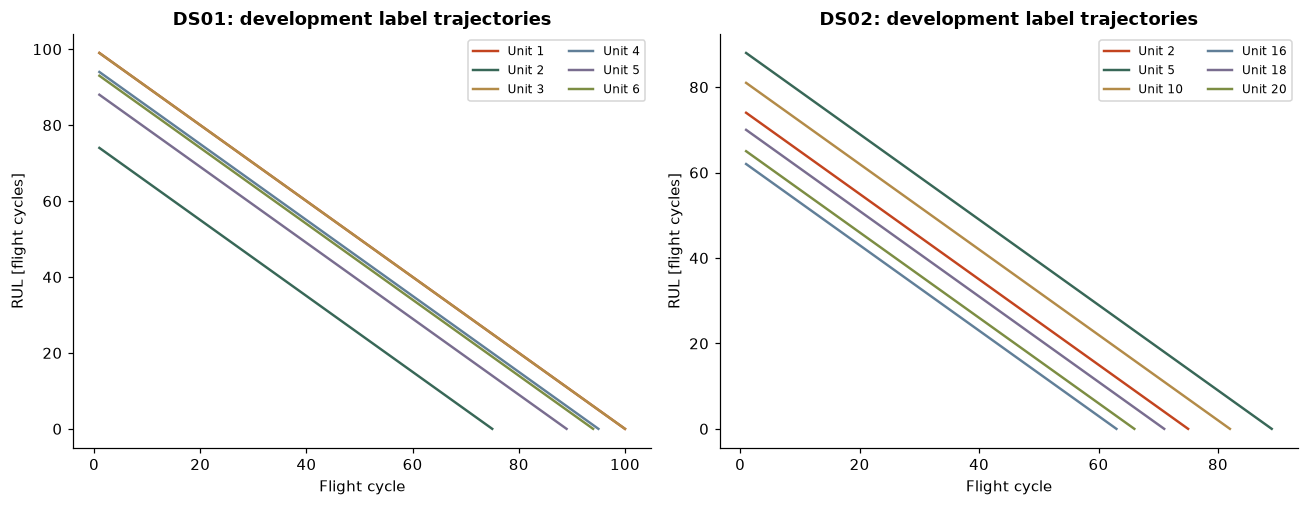

Example: DS01 unit 1, cycle 1: last cycle 100 − current cycle 1 = RUL 99.


In [8]:
display(consistency)
assert consistency.rul_formula_violations.sum() == 0, 'Investigate target formula before proceeding'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, ds in zip(axes, sorted(cycles.dataset.unique())):
    for unit, rows in cycles[(cycles.dataset==ds) & (cycles.partition=='dev')].groupby('unit'):
        ax.plot(rows.cycle, rows.RUL_min, label=f'Unit {unit}', linewidth=1.6)
    ax.set(title=f'{ds}: development label trajectories', xlabel='Flight cycle', ylabel='RUL [flight cycles]')
    ax.legend(ncol=2, fontsize=8)
save_figure(fig, 'rul_trajectories')
# Choose a real example automatically, avoiding an assumed engine ID.
example = cycles[(cycles.dataset=='DS01') & (cycles.partition=='dev')].iloc[0]
last_cycle = cycles[(cycles.dataset==example.dataset) & (cycles.unit==example.unit)].cycle.max()
print(f'Example: DS01 unit {int(example.unit)}, cycle {int(example.cycle)}: '
      f'last cycle {last_cycle} − current cycle {int(example.cycle)} = RUL {int(example.RUL_min)}.')

**What this does and does not show:** straight declining labels are the construction of the target, not evidence that a regression model can infer RUL from sensor readings. Different engines fail after different numbers of cycles, so cycle alone is not a universal countdown.

### One flight contains a whole operating trajectory
We now load just the first development flight from DS01. Its row order shows changing altitude, speed, throttle, and inlet temperature. These operating conditions can change sensor readings even when engine health has not changed.

The x-axis is an **ordered sample index**. The supplied preprint describes DS02 as 1 Hz; there is no timestamp column here to independently verify sampling intervals, gaps, or a calendar date.

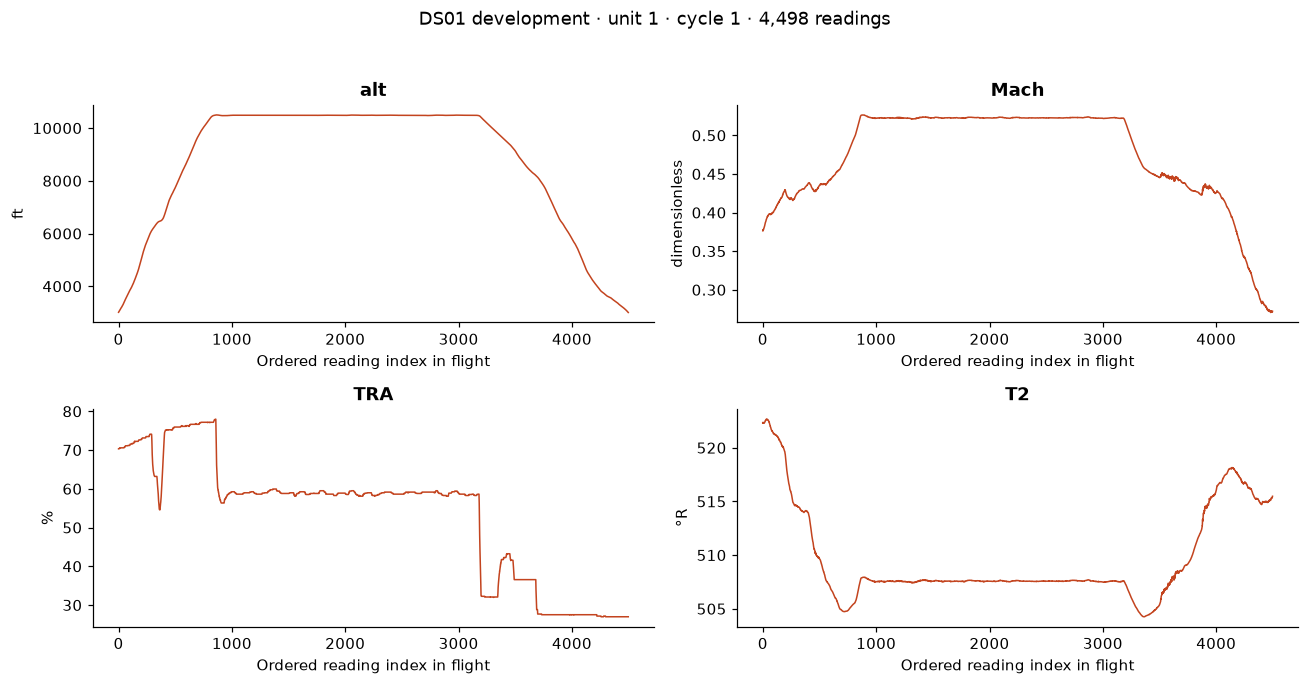

In [9]:
flight, flight_unit, flight_cycle = first_flight(PATHS[0])
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, feature, unit in zip(axes.flat, ['alt','Mach','TRA','T2'], ['ft','dimensionless','%','°R']):
    ax.plot(np.arange(len(flight)), flight[feature], linewidth=1)
    ax.set(title=feature, xlabel='Ordered reading index in flight', ylabel=unit)
fig.suptitle(f'DS01 development · unit {flight_unit} · cycle {flight_cycle} · {len(flight):,} readings', y=1.03)
save_figure(fig, 'single_flight')

### Distributions of the operating conditions
Histograms below use **12,000 evenly spaced development readings per dataset** (or fewer if a file is smaller). They represent reading-weighted observations; long flights contribute more than short flights. They do not establish exact population quantiles, and are not a formal random sample.

The source's flight classes describe short/medium/long missions (1/2/3). The unit table is an exact structural check of which classes appear in each split. If a test class is absent in development, this is a distribution-shift warning; test data must not be used to tune the model.

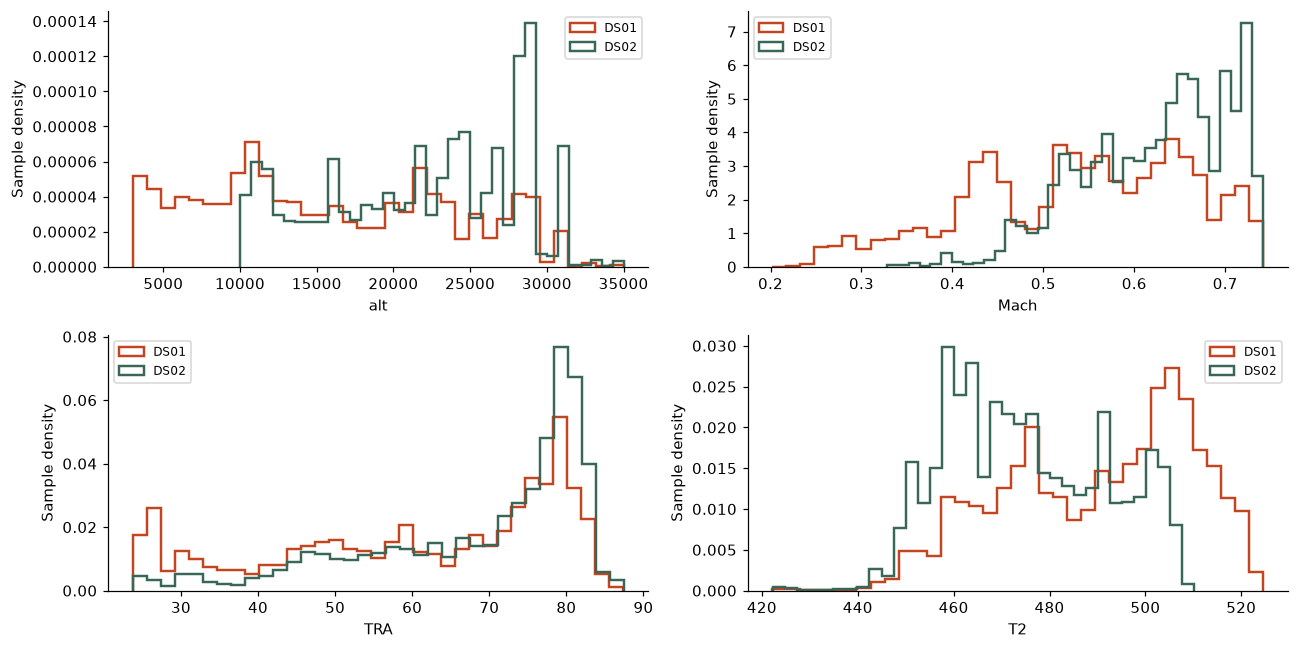

,dataset,partition,unit,flight_class,readings,cycles
0,DS01,dev,1,1.0,433325,100
1,DS01,dev,2,3.0,1049088,75
2,DS01,dev,3,2.0,893054,100
3,DS01,dev,4,1.0,414172,95
4,DS01,dev,5,3.0,1280147,89
5,DS01,dev,6,2.0,836850,94
6,DS01,test,7,1.0,392585,90
7,DS01,test,8,2.0,800294,89
8,DS01,test,9,1.0,351683,80
9,DS01,test,10,3.0,1190670,82


,dataset,partition,flight_class,engine_count
0,DS01,dev,1.0,2
1,DS01,dev,2.0,2
2,DS01,dev,3.0,2
3,DS01,test,1.0,2
4,DS01,test,2.0,1
5,DS01,test,3.0,1
6,DS02,dev,3.0,6
7,DS02,test,1.0,1
8,DS02,test,2.0,1
9,DS02,test,3.0,1


In [10]:
development = sample[sample.partition=='dev'].copy()
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, feature in zip(axes.flat, ['alt','Mach','TRA','T2']):
    for ds, rows in development.groupby('dataset'):
        ax.hist(rows[feature], bins=35, density=True, histtype='step', linewidth=1.6, label=ds)
    ax.set(xlabel=feature, ylabel='Sample density'); ax.legend(fontsize=8)
save_figure(fig, 'operating_distributions')
display(engines[['dataset','partition','unit','flight_class','readings','cycles']])
class_coverage = engines.groupby(['dataset','partition','flight_class']).size().rename('engine_count').reset_index()
display(class_coverage)

### Do sensor readings show degradation?
We plot **full-data cycle means** for DS01 development engines. Each sensor is standardized within that engine solely to compare shapes: `(cycle_mean − engine_mean) / engine_std`. This uses the full engine history and is **not an operational preprocessing pipeline**. Raw values and units remain in the statistics table.

Whole-flight averaging mixes climb, cruise, and descent; a trend can reflect changes in operating conditions as well as degradation. A later preparation step might compare matched operating phases or use operating-condition features. Do not claim that a plotted trend isolates causal wear.

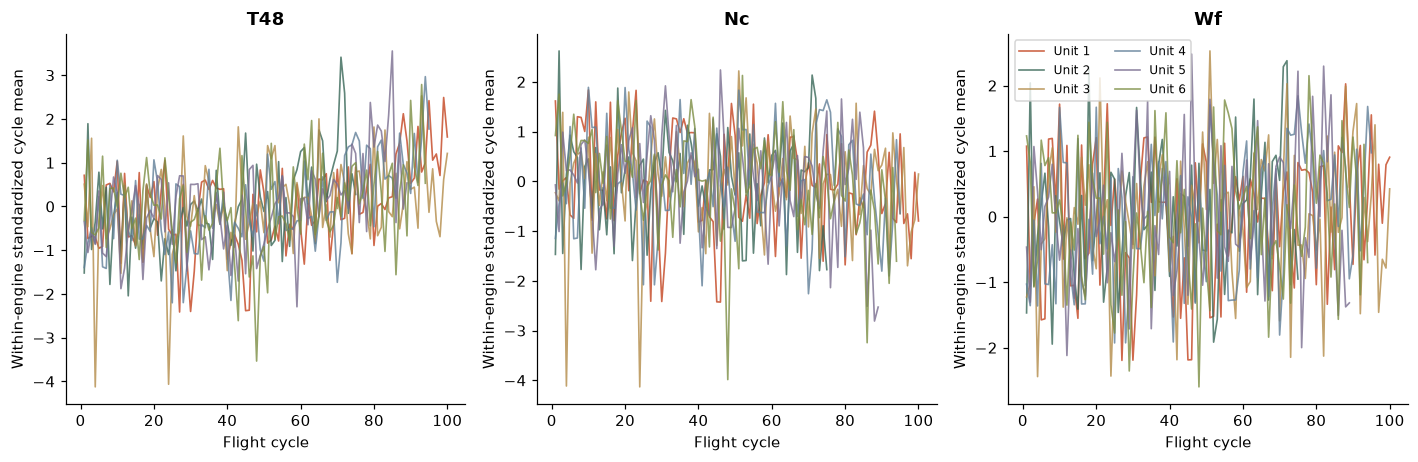

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, sensor in zip(axes, ['T48','Nc','Wf']):
    for unit, rows in cycles[(cycles.dataset=='DS01') & (cycles.partition=='dev')].groupby('unit'):
        values=rows[sensor + '_mean']
        z=(values-values.mean()) / values.std() if values.std() > 0 else values*0
        ax.plot(rows.cycle, z, label=f'Unit {unit}', linewidth=1.1, alpha=.8)
    ax.set(title=sensor, xlabel='Flight cycle', ylabel='Within-engine standardized cycle mean')
axes[-1].legend(ncol=2, fontsize=8)
save_figure(fig, 'sensor_cycle_trends')

### Correlation is a clue, not a cause
The heatmap uses only **DS01 development sample rows** and Pearson correlation for candidate predictors plus the target. Operating conditions, engine differences, and repeated time samples can all drive correlations. We do not calculate p-values as though these were independent observations.

A high sensor–RUL correlation does not prove causal degradation or guarantee prediction on unseen engines. A low linear correlation does not rule out nonlinear relationships. `T`, `X_v`, `hs`, IDs, and cycle are excluded from this candidate-feature heatmap.

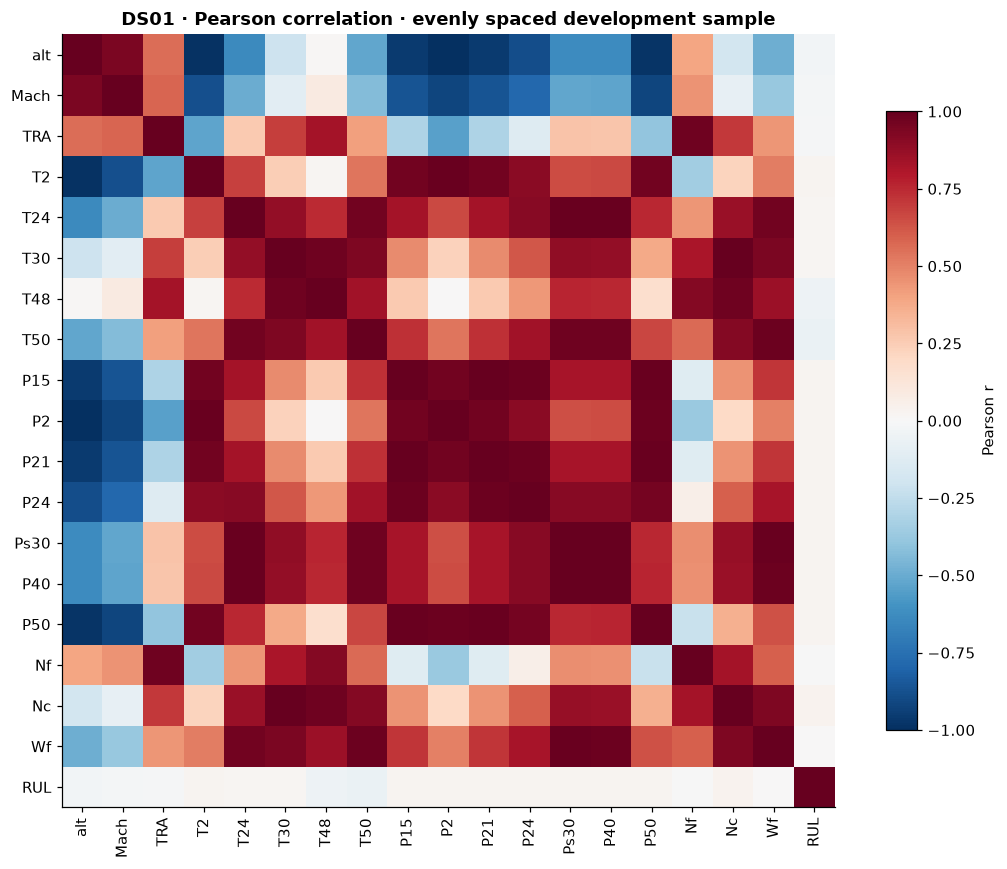

In [12]:
candidate_columns = dictionary.loc[dictionary.group.isin(['W','X_s']), 'feature'].tolist()
corr = development[development.dataset=='DS01'][candidate_columns + ['RUL']].corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
ax.set_title('DS01 · Pearson correlation · evenly spaced development sample')
fig.colorbar(image, ax=ax, label='Pearson r', shrink=.8)
save_figure(fig, 'development_correlation')
corr.to_csv(RESULTS / 'ds01_development_sample_correlations.csv')

### Are extreme values automatically bad data?
No. An unusual altitude, temperature, or operating point can be valid. The Tukey/IQR screen flags values outside `[Q1 − 1.5×IQR, Q3 + 1.5×IQR]` using the development sample, separately by dataset. Mixed flight regimes can make ordinary values appear extreme.

The screen is descriptive, not a deletion rule. No rows are removed or imputed. It covers `W`, `X_s`, and `X_v`; IDs, categorical codes, health modifiers, and target labels are not meaningful candidates for this generic fence.

,dataset,feature,sample_rows,q1,q3,iqr,flagged,flagged_pct
47,DS02,Nf,12000,1958.415819,2111.614451,153.198632,603,5.025000
28,DS01,SmFan,12000,17.569701,19.717248,2.147548,592,4.933333
63,DS02,phi,12000,37.637082,40.125644,2.488563,540,4.500000
62,DS02,SmHPC,12000,26.410769,28.758192,2.347423,502,4.183333
17,DS01,Wf,12000,1.985399,2.930253,0.944854,460,3.833333
50,DS02,T40,12000,2473.017129,2626.002186,152.985058,449,3.741667
49,DS02,Wf,12000,1.868285,2.557008,0.688723,438,3.650000
38,DS02,T48,12000,1593.095661,1700.352177,107.256517,417,3.475000
60,DS02,SmFan,12000,18.167492,19.958724,1.791232,385,3.208333
20,DS01,P45,12000,36.335606,50.829849,14.494243,320,2.666667


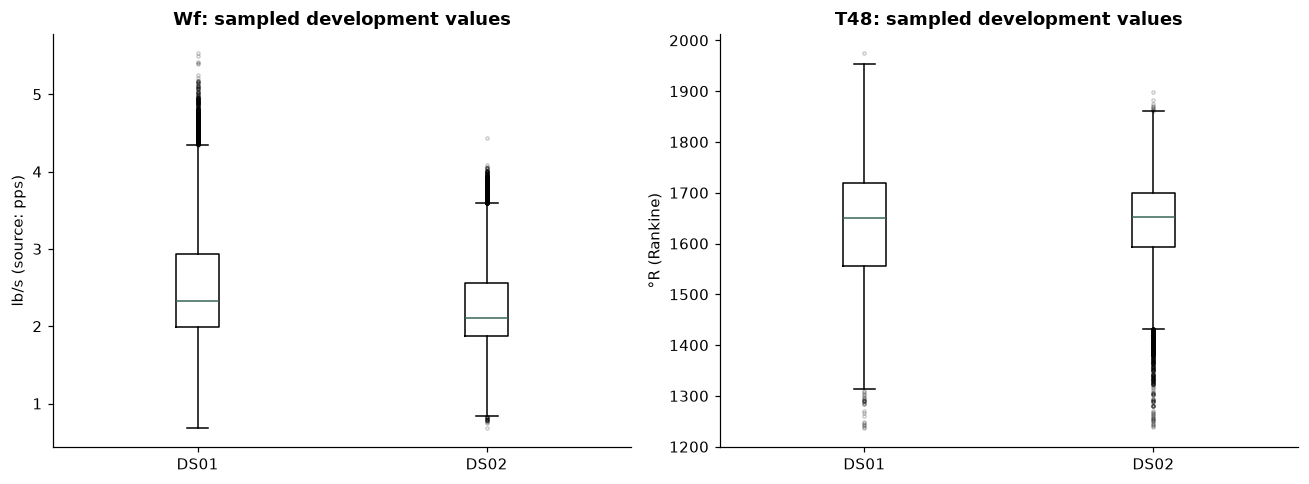

In [13]:
outliers = outlier_screen(sample)
display(outliers.sort_values('flagged_pct', ascending=False).head(15))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feature in zip(axes, ['Wf','T48']):
    data=[rows[feature].to_numpy() for _,rows in development.groupby('dataset')]
    ax.boxplot(data, tick_labels=sorted(development.dataset.unique()), showfliers=True,
               flierprops={'markersize':2,'alpha':.2})
    ax.set(title=f'{feature}: sampled development values', ylabel=dictionary.set_index('feature').loc[feature,'unit'])
save_figure(fig, 'sensor_distributions')

## 6 · Data quality — six dimensions, with honest limits
The lecturer's “Verify Data Quality” excerpt distinguishes conformity, completeness, uniqueness, accuracy, timeliness, and consistency. Passing numerical checks is not a certificate of physical accuracy.

- **Conformity:** shapes/types/column membership and coded field domains. Floating-point storage of an ID is acceptable when values are positive integers.
- **Completeness:** NaN and ±infinity scanned across every numeric cell. This does not establish absence of sentinels or missing time intervals.
- **Uniqueness:** adjacent exact-row duplication across full data (including chunk boundaries), plus exact-row duplicates in the bounded diagnostic sample. Non-adjacent global duplicates have not been exhaustively checked. Repeated engine-flight keys are expected.
- **Accuracy:** full ranges and development-sample IQR flags. Without physical reference measurements, correctness cannot be established; no automatic outlier removal.
- **Timeliness:** static simulated histories with no calendar timestamps; dataset vintage and download provenance must be distinguished from deployment freshness.
- **Consistency:** disjoint engines within provided splits; integer IDs/cycles; categorical domains; cycle ordering/continuity; health-state direction; RUL constancy and exact retrospective countdown per engine.

In [14]:
missing_total = int(stats.missing.sum())
infinite_total = int(stats.infinite.sum())
logic_columns = ['inconsistent_rul_cycles','rul_formula_violations','noncontiguous_cycles',
                 'health_switch_back','mixed_health_cycles','mixed_flight_class_cycles']
logic_total = int(consistency[logic_columns].sum().sum())
quality = pd.DataFrame([
 {'dimension':'Conformity','scope':'Full metadata + all auxiliary codes',
  'finding':f"Arrays aligned; invalid category codes: {int(checks.invalid_categories.sum())}; invalid IDs/cycles: {int(checks.invalid_indices.sum())}",
  'limitation':'P2 definition/unit requires source confirmation; file metadata does not prove physical units.'},
 {'dimension':'Completeness','scope':'Every numeric cell in both files',
  'finding':f'NaN: {missing_total}; infinity: {infinite_total}',
  'limitation':'Sentinel values and gaps in physical time are not established by NaN checks.'},
 {'dimension':'Uniqueness','scope':'All adjacent rows + 12,000 evenly spaced rows per partition',
  'finding':f"Adjacent exact duplicates: {int(checks.adjacent_exact_duplicates.sum())}; sampled exact duplicates: {int(checks.sample_exact_duplicates.sum())}",
  'limitation':'All non-adjacent duplicates were not exhaustively checked; repeated flight keys are valid.'},
 {'dimension':'Accuracy','scope':'Full ranges + development-sample IQR screens',
  'finding':f'{int((outliers.flagged>0).sum())} dataset-variable pairs have sampled IQR flags; no rows removed',
  'limitation':'Extreme values are not proven errors; no independent physical ground truth.'},
 {'dimension':'Timeliness','scope':'Provided sources and metadata',
  'finding':'Static simulation data; no calendar timestamp column',
  'limitation':'Download version/terms remain to be recorded; current operational relevance is unvalidated.'},
 {'dimension':'Consistency','scope':'All engine-flight aggregates + full auxiliary scan',
  'finding':f'Engine overlap: {overlap}; cycle/label/health checks flagged: {logic_total}',
  'limitation':'Both partitions were inspected for understanding; keep test data out of later tuning.'},
])
display(quality)
print('Cycle-order reversals within a unit:', int(checks.within_unit_cycle_reversals.sum()))
print('Audit coverage:', int(stats.rows.sum()), 'numeric cells across', int(checks.rows.sum()), 'readings')

,dimension,scope,finding,limitation
0,Conformity,Full metadata + all auxiliary codes,Arrays aligned; invalid category codes: 0; inv...,P2 definition/unit requires source confirmatio...
1,Completeness,Every numeric cell in both files,NaN: 0; infinity: 0,Sentinel values and gaps in physical time are ...
2,Uniqueness,"All adjacent rows + 12,000 evenly spaced rows ...",Adjacent exact duplicates: 0; sampled exact du...,All non-adjacent duplicates were not exhaustiv...
3,Accuracy,Full ranges + development-sample IQR screens,49 dataset-variable pairs have sampled IQR fla...,Extreme values are not proven errors; no indep...
4,Timeliness,Provided sources and metadata,Static simulation data; no calendar timestamp ...,Download version/terms remain to be recorded; ...
5,Consistency,All engine-flight aggregates + full auxiliary ...,"Engine overlap: {'DS01': [], 'DS02': []}; cycl...",Both partitions were inspected for understandi...


Cycle-order reversals within a unit: 0
Audit coverage: 665475726 numeric cells across 14159058 readings


## 7 · What can we conclude, and what comes later?
**Observed:** the exported tables and figures establish structure, labels, engine-level partitions, distributions, and the stated quality checks for these two local files. They do not describe every N-CMAPSS group.

**Working choice:** start with DS01 development engines, use `W` + `X_s`, preserve unit grouping, and consider end-of-flight predictions using current-flight summaries. This is a manageable proposal, not a completed preparation decision. Finalize it with the team before modeling. DS02 is a useful later robustness case because its operating classes can differ between development and test.

**Avoid leakage:** never use future cycles, engine's known final lifetime, true RUL, simulator health modifiers, or retrospective health labels as predictors. Fit scaling/imputation/feature selection on development training engines only. Validate on separate development engines; preserve the provided test engines for final evaluation. This exploratory inspection has already exposed test structure and labels, so we must document that exposure and refrain from adaptive tuning to test results.

No MAE/RMSE has been computed: those belong to later trained-model evaluation. No savings, aviation safety suitability, or real-world validation is inferred here.

### Practise answering these questions
| Question | Explain using |
|---|---|
| What is the business question? | Whether RUL estimates could inform maintenance planning; no demonstrated savings |
| Are these actual engine failures? | No: simulated degradation/sensor responses driven by real operating profiles |
| What is a row? | One aligned operating/sensor reading; many rows occur inside one flight |
| How many independent engines do we have? | Engine table, not the total row count; IDs are dataset-scoped |
| What does RUL 0 mean? | The final simulated flight cycle under the verified label convention |
| Why is unit stored as float64? | Storage representation differs from nominal statistical meaning |
| Why do temperatures have unusual values? | Absolute Rankine units; never silently interpret as °C |
| Can we train on all 47 fields? | No: candidate W + X_s only; others include target, metadata, hidden state |
| Why are repeated unit/cycle pairs not duplicate errors? | A full flight contains many sensor readings |
| What quality problems were found? | Read the six-dimension table; state full vs sampled coverage and unknowns |
| Why can an outlier be valid? | Different operating regimes; a statistical fence is not a physical error bound |
| Why can long-flight engines dominate? | More rows per flight; show readings vs flight counts |
| Why avoid random row splitting? | Same engine and neighboring readings could appear in both train and validation |
| Does correlation mean degradation causes the sensor change? | No; operating conditions and engine differences confound it |
| Why is DS02 a different challenge? | Compare exact unit/flight-class coverage; discuss held-out operating regimes |
| What is not yet known? | Upstream version/license, P2 source definition, real-world accuracy, model performance |

**Try it:** explain one complete flight using the single-flight figure, one lifetime using the RUL plot, and one limitation using the quality table. If an answer is unclear, return to the corresponding cell instead of memorizing a number.

### Export small, reviewable evidence
The CSVs hold aggregates, not raw measurement arrays. SHA-256 hashes identify the precise files (one extra sequential read); they do not certify the Kaggle source. The JSON records the environment, configuration, counts, and audit scope used by the report/page generator.

After running this notebook, regenerate the human-facing report and findings page from the repository root with:
```bash
python scripts/build_task3_report.py
```
Review the generated text and figures together before using them in the presentation.

In [15]:
manifest = source_manifest(PATHS)
for name, table in [('inventory',inventory), ('statistics',stats), ('cycles',cycles),
                    ('engines',engines), ('checks',checks), ('consistency',consistency),
                    ('outlier_screen',outliers), ('quality',quality), ('overview',overview)]:
    table.to_csv(RESULTS / f'{name}.csv', index=False)
summary = dict(analysis_date=ANALYSIS_DATE, files=manifest, environment=versions,
               configuration={'chunk_rows':CHUNK_ROWS, 'sample_rows_per_partition':SAMPLE_ROWS,
                              'sampling':'deterministic evenly spaced by original row index'},
               overview=json.loads(overview.to_json(orient='records')),
               checks=json.loads(checks.to_json(orient='records')),
               quality=json.loads(quality.to_json(orient='records')),
               totals={'readings':int(checks.rows.sum()),'numeric_cells':int(stats.rows.sum()),
                       'engines':len(engines),'flights':len(cycles),
                       'missing':missing_total,'infinite':infinite_total,
                       'adjacent_exact_duplicates':int(checks.adjacent_exact_duplicates.sum()),
                       'sample_exact_duplicates':int(checks.sample_exact_duplicates.sum()),
                       'cycle_logic_flags':logic_total},
               test_engine_overlap=overlap,
               limitations=['No global non-adjacent duplicate proof', 'No physical accuracy validation',
                            'No explicit timestamps', 'P2 definition/unit unconfirmed',
                            'Upstream version and Kaggle redistribution terms unverified',
                            'No trained models or prediction metrics'])
(RESULTS / 'task3_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
(RESULTS / 'environment.json').write_text(json.dumps(versions, indent=2) + '\n')
print('Exported evidence to', RESULTS.relative_to(ROOT))
display(pd.DataFrame(manifest))

Exported evidence to reports/results


,file,bytes,sha256
0,N-CMAPSS_DS01-005.h5,2873351432,3abdcee2a3c8136e8880e5d43ac8cdf12ab9f7f3ab3714...
1,N-CMAPSS_DS02-006.h5,2450472504,47971a68b239ecb756833218a95d68ded6eb7e63ee84e8...
